# Schbib et al. (1996): steady-state laboratory PFR benchmark

This notebook implements a one-dimensional, steady-state, isobaric and adiabatic plug-flow model for acetylene semi-hydrogenation and ethylene over-hydrogenation. It uses the simplified Schbib rate equations and fixed parameters reported in the primary article; no kinetic parameters are fitted here.

The solver integrates molar flows and gas temperature along bed coordinate (z). Kinetic rates are per gram of catalyst. The bed catalyst loading is represented by (
ho_s(1-arepsilon_b)), using the real catalyst density and the reported catalyst porosity as the effective solids fraction. The paper does not report an interparticle void fraction or loaded bed length, so the resulting (z) scale is a one-dimensional bed-equivalent coordinate, not a measured packing geometry.

This is the pseudohomogeneous adiabatic model specified in `GOAL.md`; the laboratory used a glycol bath, and the paper's laboratory model III includes external heat and mass transfer. This notebook therefore reproduces the requested simplified model and reports any difference from measured Table 6 conversions without retuning the source kinetics.

## Literature data and provenance

Primary source: Schbib, N. S.; García, M. A.; Gígola, C. E.; Errazu, A. F., “Kinetics of Front-End Acetylene Hydrogenation in Ethylene Production,” *Industrial & Engineering Chemistry Research* 35 (1996), 1496–1503. Values below were transcribed from `research/literature/schbib_1996_full_article.html` and checked against `research/literature/schbib_1996_extracted_text.txt`.

**Table 3, laboratory feed and operating envelope:** CH₄ 6.53 mol%; C₂H₂ 0.52 mol%; C₂H₄ 43.99 mol%; C₂H₆ 26.72 mol%; H₂ 22.1 mol%; CO 150–5000 ppm; flow 100 cm³(STP)/min; catalyst mass 1–3 g; pressure 1–35 atm; temperature 288–393 K. The listed non-CO feed fractions sum to 99.86% because of rounding. For calculations they are normalized to (1-y_{CO}), with CO represented at its stated feed ppm.

**Table 4, ICI 38-1 catalyst:** α-Al₂O₃ support; Pd 0.04 wt%; BET area 21 m²/g; H/Pd dispersion 0.15; apparent density 1.61 g/cm³; real density 3.61 g/cm³; mean pore diameter 1000 Å; pore volume 0.338 cm³/g; porosity 54.5%. We use (
ho_s=3.61) g/cm³ and (arepsilon_b=0.545), giving an effective loading of 1.64255 g/cm³, close to the measured apparent density. No separate interparticle void fraction is reported.

**Table 6, fixed-pressure CO benchmark:** pressure 16 atm and space velocity 100 cm³(STP) gcat⁻¹ min⁻¹. Reported conversions are listed in the validation table generated below.

**Table 8, kinetic parameters:** the table lists (log A_i) and (E_i) in kcal/gmol. The common-log interpretation is used, (A_i=10^{log A_i}), followed by (k_i=A_iexp(-E_i/RT)). The article's full denominator also lists (K_E), (K_{Et}), and (K_A); the text immediately below Table 8 says these hydrocarbon adsorption terms have a negligible effect and simplifies the equations to the H₂/CO denominator used here. All Table 8 values are retained in this source ledger.

| Parameter | (log_{10} A_i) | (E_i) (kcal/gmol) | Units of (A_i) |
|---|---:|---:|---|
| (k_A) | 31.1 | 45.51 | m⁶/(s gcat kmol) |
| (k_E) | 26.6 | 42.94 | m⁶/(s gcat kmol) |
| (K_H) | 20.2 | 21.22 | m³/kmol |
| (K_{CO}) | 13.6 | 9.95 | m³/kmol |
| (K_E) (omitted in simplified law) | 0.26 | 0.005 | m³/kmol |
| (K_{Et}) (omitted in simplified law) | −0.012 | 0.001 | m³/kmol |
| (K_A) (omitted in simplified law) | −16 | 0.001 | m³/kmol |

The reaction heats used in the energy balance, (-172) and (-136) kJ/mol, are supplied by `GOAL.md`; they are not values from Tables 3, 4, 6, or 8. Gas heat capacities use the NASA7 coefficients for CH₄, C₂H₂, C₂H₄, C₂H₆, H₂, and CO in GRI-Mech 3.0 `gri30.yaml` (Cantera data repository, `https://github.com/Cantera/cantera/blob/main/data/gri30.yaml`), valid here over 200–1000 K. STP is taken as 273.15 K and 1 atm. These assumptions are explicit because the article does not specify a different STP convention or provide the heat-capacity coefficients.

## Model equations and units

The two positive reaction rates per catalyst mass are

\[
r_1=\frac{k_A C_{C_2H_2}C_{H_2}}{D^3},\qquad
r_2=\frac{k_E C_{C_2H_4}C_{H_2}}{D^3},\qquad
D=1+(K_H C_{H_2})^{1/2}+K_{CO}C_{CO}.
\]

The state contains molar flow (F_i) in kmol/s for every feed species and gas temperature (T) in K. Concentrations are ideal-gas values in kmol/m³ at the specified constant pressure. Rates are kmol/(gcat s), so

\[
\frac{d\mathbf F}{dz}=A\rho_s(1-\varepsilon_b)\,\boldsymbol\nu\mathbf r,
\qquad
\frac{dT}{dz}=\frac{A\rho_s(1-\varepsilon_b)\sum_j(-\Delta H_j)r_j}{\sum_i F_i C_{p,i}}.
\]

Here (A) is tube cross-sectional area, (C_p) is in kJ/(kmol K) (numerically equal to J/(mol K)), and heats are converted from kJ/mol to kJ/kmol. The 10 mm tube inside diameter is reported in the article's experimental section. Reaction-specific conversions are calculated from extents: acetylene disappearance for reaction 1 and ethane formation for reaction 2. This avoids treating net ethylene flow change as ethylene conversion when reaction 1 also forms ethylene.

In [1]:
import sys
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

from dataclasses import dataclass
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

R_J_MOL_K = 8.314462618  # J mol-1 K-1
R_PA_M3_KMOL_K = 8314.462618  # Pa m3 kmol-1 K-1
R_KJ_KMOL_K = 8.314462618  # kJ kmol-1 K-1
P_ATM_PA = 101325.0
T_STP_K = 273.15
P_STP_PA = P_ATM_PA
TUBE_ID_M = 0.010  # article experimental section: 10 mm i.d.
SPECIES = ("CH4", "C2H2", "C2H4", "C2H6", "H2", "CO")
SPECIES_INDEX = {name: i for i, name in enumerate(SPECIES)}

# Table 3 molar percentages. CO is supplied separately in ppm.
BASE_FEED = np.array([0.0653, 0.0052, 0.4399, 0.2672, 0.2210, 0.0])

# Table 8: (log10(A), E[kcal/gmol]); all values are transcribed above.
KINETIC_DATA = {
    "k_A": (31.1, 45.51),
    "k_E": (26.6, 42.94),
    "K_H": (20.2, 21.22),
    "K_CO": (13.6, 9.95),
}
TABLE8_OMITTED_TERMS = {
    "K_E": (0.26, 0.005),
    "K_Et": (-0.012, 0.001),
    "K_A": (-16.0, 0.001),
}
DELTA_H_KJ_KMOL = np.array([172_000.0, 136_000.0])  # Goal: -172, -136 kJ/mol

# Element rows C, H, O; columns are species in SPECIES order.
ELEMENTS = np.array([
    [1, 2, 2, 2, 0, 1],
    [4, 2, 4, 6, 2, 0],
    [0, 0, 0, 0, 0, 1],
], dtype=float)
STOICH = np.array([
    [0, 0],   # CH4
    [-1, 0],  # C2H2
    [1, -1], # C2H4
    [0, 1],  # C2H6
    [-1, -1],# H2
    [0, 0],  # CO
], dtype=float)

# NASA7 low-temperature coefficients, Cp/R = a1+a2*T+a3*T^2+a4*T^3+a5*T^4.
# Transcribed from Cantera's GRI-Mech 3.0 gri30.yaml; applicable interval 200-1000 K.
NASA7 = {
    "CH4": [5.14987613, -1.36709788e-2, 4.91800599e-5, -4.84743026e-8, 1.66693956e-11],
    "C2H2": [0.808681094, 2.33615629e-2, -3.55171815e-5, 2.80152437e-8, -8.50072974e-12],
    "C2H4": [3.95920148, -7.57052247e-3, 5.70990292e-5, -6.91588753e-8, 2.69884373e-11],
    "C2H6": [4.29142492, -5.5015427e-3, 5.99438288e-5, -7.08466285e-8, 2.68685771e-11],
    "H2": [2.34433112, 7.98052075e-3, -1.9478151e-5, 2.01572094e-8, -7.37611761e-12],
    "CO": [3.57953347, -6.1035368e-4, 1.01681433e-6, 9.07005884e-10, -9.04424499e-13],
}

@dataclass(frozen=True)
class ModelParams:
    """Steady PFR inputs; rates are per gram of catalyst."""
    pressure_atm: float
    T0_K: float
    CO_ppm: float
    catalyst_mass_g: float
    flow_stp_cm3_min: float = 100.0
    tube_ID_m: float = TUBE_ID_M
    rho_s_g_m3: float = 3.61e6  # Table 4 real density, g/m3
    epsilon_b: float = 0.545    # Table 4 reported porosity used per Goal
    rtol: float = 1e-8
    atol: float = 1e-13
    n_points: int = 240

    @property
    def area_m2(self):
        return np.pi * (self.tube_ID_m / 2.0) ** 2

    @property
    def catalyst_loading_g_m3(self):
        return self.rho_s_g_m3 * (1.0 - self.epsilon_b)

    @property
    def bed_length_m(self):
        return self.catalyst_mass_g / (self.area_m2 * self.catalyst_loading_g_m3)

    @property
    def pressure_Pa(self):
        return self.pressure_atm * P_ATM_PA

    @property
    def space_velocity_cm3_g_min(self):
        return self.flow_stp_cm3_min / self.catalyst_mass_g

def arrhenius(log10_A, E_kcal_mol, T_K):
    """Convert the tabulated common-log pre-exponential and kcal/mol E to SI rates."""
    return 10.0 ** log10_A * np.exp(-(E_kcal_mol * 4184.0) / (R_J_MOL_K * T_K))

def heat_capacity_j_mol_k(T_K):
    """Return ideal-gas Cp for SPECIES using NASA7 polynomials (200-1000 K)."""
    if not 200.0 <= T_K <= 1000.0:
        raise ValueError(f"NASA7 coefficient range is 200-1000 K; received {T_K:.2f} K")
    cp = []
    for species in SPECIES:
        a1, a2, a3, a4, a5 = NASA7[species]
        cp_over_R = a1 + a2*T_K + a3*T_K**2 + a4*T_K**3 + a5*T_K**4
        cp.append(cp_over_R * R_J_MOL_K)
    return np.asarray(cp)

def feed_mole_fractions(p):
    """Normalize rounded Table 3 fractions and add the specified CO ppm."""
    y_co = p.CO_ppm * 1e-6
    y = BASE_FEED.copy()
    y[-1] = y_co
    y[:-1] *= (1.0 - y_co) / y[:-1].sum()
    return y

def inlet_flows_kmol_s(p):
    """Convert the Table 3 STP volumetric feed to kmol/s."""
    q_m3_s = p.flow_stp_cm3_min * 1e-6 / 60.0
    total_kmol_s = q_m3_s * P_STP_PA / (R_PA_M3_KMOL_K * T_STP_K)
    return total_kmol_s * feed_mole_fractions(p)

def concentrations_kmol_m3(flows_kmol_s, T_K, p):
    flows = np.maximum(np.asarray(flows_kmol_s), 0.0)
    total = flows.sum()
    if total <= 0.0:
        raise ValueError("Total molar flow must remain positive")
    y = flows / total
    return y * p.pressure_Pa / (R_PA_M3_KMOL_K * T_K)

def calculate_rates(flows_kmol_s, T_K, p):
    """Schbib simplified Eq. 24-25; returns r1, r2 in kmol/(gcat s)."""
    C = concentrations_kmol_m3(flows_kmol_s, T_K, p)
    c_a = C[SPECIES_INDEX["C2H2"]]
    c_e = C[SPECIES_INDEX["C2H4"]]
    c_h = C[SPECIES_INDEX["H2"]]
    c_co = C[SPECIES_INDEX["CO"]]
    k_a = arrhenius(*KINETIC_DATA["k_A"], T_K)
    k_e = arrhenius(*KINETIC_DATA["k_E"], T_K)
    k_h = arrhenius(*KINETIC_DATA["K_H"], T_K)
    k_co = arrhenius(*KINETIC_DATA["K_CO"], T_K)
    denominator = 1.0 + np.sqrt(max(k_h * c_h, 0.0)) + k_co * c_co
    r1 = k_a * c_a * c_h / denominator**3
    r2 = k_e * c_e * c_h / denominator**3
    return np.array([r1, r2]), denominator

def ode_rhs(z_m, state, p):
    """Legacy Reactor Format: dF_i/dz and dT/dz for the isobaric adiabatic bed."""
    flows = np.maximum(state[:-1], 0.0)
    T_K = float(state[-1])
    rates, _ = calculate_rates(flows, T_K, p)
    volumetric_rate = p.area_m2 * p.catalyst_loading_g_m3
    dF_dz = volumetric_rate * (STOICH @ rates)
    cp = heat_capacity_j_mol_k(T_K)  # numerically kJ/(kmol K)
    heat_capacity_flow = np.dot(flows, cp)
    dT_dz = volumetric_rate * np.dot(DELTA_H_KJ_KMOL, rates) / heat_capacity_flow
    return np.concatenate([dF_dz, [dT_dz]])

def run_pfr(p):
    """Integrate one case with the stiff Radau solver."""
    y0 = np.concatenate([inlet_flows_kmol_s(p), [p.T0_K]])
    z = np.linspace(0.0, p.bed_length_m, p.n_points)
    solution = solve_ivp(
        ode_rhs, (0.0, p.bed_length_m), y0, args=(p,), method="Radau",
        t_eval=z, rtol=p.rtol, atol=p.atol, max_step=p.bed_length_m / 60.0,
    )
    if not solution.success:
        raise RuntimeError(f"Radau failed: {solution.message}")
    return solution

def conversion_profiles(solution, p):
    """Reaction-specific conversions from stoichiometric extents."""
    f0 = inlet_flows_kmol_s(p)
    states = solution.y
    x_a = (f0[SPECIES_INDEX["C2H2"]] - states[SPECIES_INDEX["C2H2"]]) / f0[SPECIES_INDEX["C2H2"]]
    xi2 = states[SPECIES_INDEX["C2H6"]] - f0[SPECIES_INDEX["C2H6"]]
    x_e = xi2 / f0[SPECIES_INDEX["C2H4"]]
    return np.clip(x_a, 0.0, 1.0), np.clip(x_e, 0.0, 1.0)

print(f"Python: {sys.version.split()[0]}; NumPy {np.__version__}; SciPy {__import__('scipy').__version__}")

Python: 3.12.14; NumPy 2.3.5; SciPy 1.17.0


## Structural checks and one baseline solution

The element matrix must annihilate the reaction stoichiometry. The baseline case uses the Table 6 space velocity (100 cm³(STP) gcat⁻¹ min⁻¹), pressure 16 atm, 1400 ppm CO, and inlet temperature 359 K.

In [2]:
assert np.allclose(ELEMENTS @ STOICH, 0.0)
assert abs(BASE_FEED[:-1].sum() - 0.9986) < 1e-12

baseline = ModelParams(pressure_atm=16.0, T0_K=359.0, CO_ppm=1400.0, catalyst_mass_g=1.0)
baseline_solution = run_pfr(baseline)
assert np.isfinite(baseline_solution.y).all()
assert baseline_solution.y[-1].min() >= 200.0
assert baseline_solution.y[-1].max() <= 1000.0
assert np.min(baseline_solution.y[:-1]) >= -1e-10
element_flows = ELEMENTS @ baseline_solution.y[:-1]
assert np.allclose(element_flows, element_flows[:, [0]], rtol=1e-8, atol=1e-12)

baseline_rates, baseline_denominator = calculate_rates(
    baseline_solution.y[:-1, -1], baseline_solution.y[-1, -1], baseline
)
assert baseline_denominator > 0.0
print(f"Baseline bed-equivalent length: {baseline.bed_length_m*100:.3f} cm")
print(f"Effective catalyst loading: {baseline.catalyst_loading_g_m3/1e6:.4f} g/cm³")
print(f"Baseline outlet temperature: {baseline_solution.y[-1,-1]:.3f} K")
print(f"Baseline outlet rates [kmol/(gcat s)]: {baseline_rates}")

Baseline bed-equivalent length: 0.775 cm
Effective catalyst loading: 1.6425 g/cm³
Baseline outlet temperature: 359.002 K
Baseline outlet rates [kmol/(gcat s)]: [3.81487435e-14 3.74440629e-15]


## Figure 1 — conversions versus inlet temperature

The article caption specifies SV = 33 cm³(STP) gcat⁻¹ min⁻¹, 800 ppm CO, and 1 and 9 atm. We retain the Table 3 flow of 100 cm³(STP)/min and use 3 g catalyst, giving 33.3 cm³(STP) gcat⁻¹ min⁻¹ (the caption's rounded value). The plotted temperature is the reactor inlet setpoint; the model then predicts the adiabatic outlet conversions.

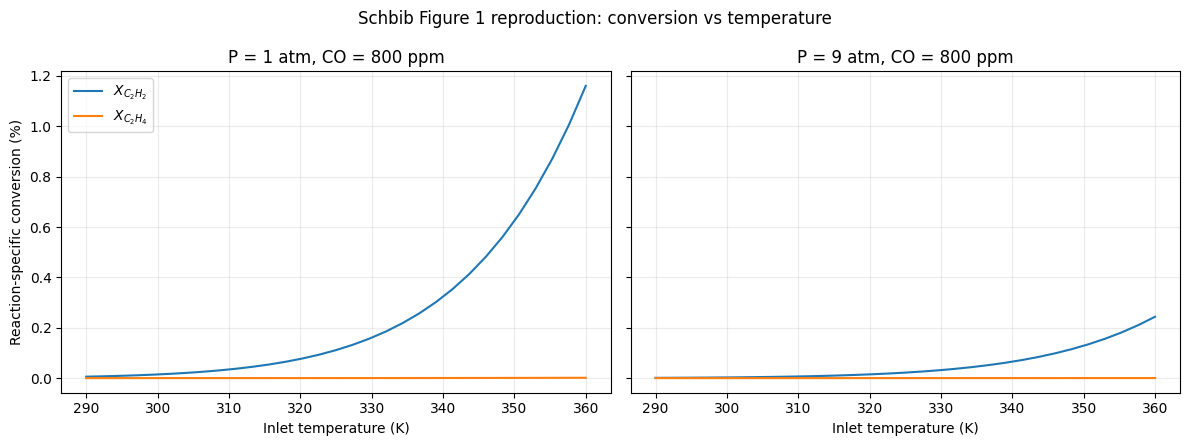

In [3]:
fig1_data = {}
for pressure_atm in (1.0, 9.0):
    rows = []
    for T0 in np.linspace(290.0, 360.0, 31):
        p = ModelParams(pressure_atm=pressure_atm, T0_K=float(T0), CO_ppm=800.0, catalyst_mass_g=3.0)
        sol = run_pfr(p)
        x_a, x_e = conversion_profiles(sol, p)
        rows.append((T0, x_a[-1] * 100.0, x_e[-1] * 100.0))
    fig1_data[pressure_atm] = np.asarray(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, pressure_atm in zip(axes, (1.0, 9.0)):
    data = fig1_data[pressure_atm]
    ax.plot(data[:, 0], data[:, 1], label=r"$X_{C_2H_2}$")
    ax.plot(data[:, 0], data[:, 2], label=r"$X_{C_2H_4}$")
    ax.set(title=f"P = {pressure_atm:g} atm, CO = 800 ppm", xlabel="Inlet temperature (K)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Reaction-specific conversion (%)")
axes[0].legend()
fig.suptitle("Schbib Figure 1 reproduction: conversion vs temperature")
fig.tight_layout()
fig.savefig("schbib_fig1_conversion_temperature.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 2 — reaction rates versus local temperature

The source caption specifies an adiabatic run with Table 3 feed, (T_0=325) K, (P=16.3) atm, and (C_{CO}=1400) ppm. The caption does not report space velocity; this reproduction uses the Table 6 value of 100 cm³(STP) gcat⁻¹ min⁻¹ (100 cm³/min and 1 g catalyst). Rates are plotted against local temperature rise T − T₀; local gas temperature is 325 K + (T − T₀).

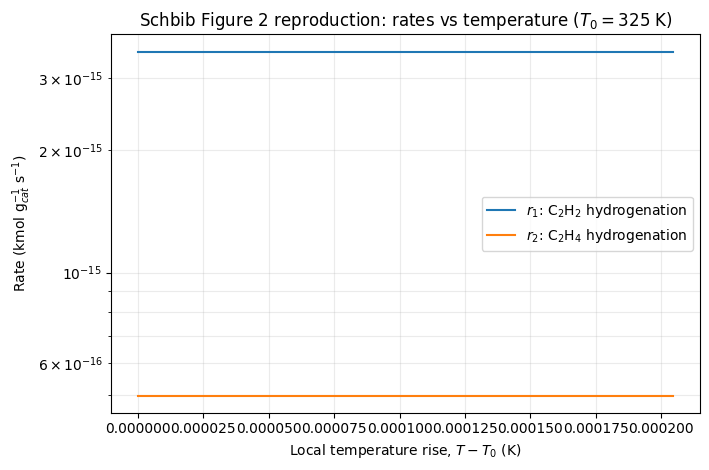

In [4]:
fig2_params = ModelParams(pressure_atm=16.3, T0_K=325.0, CO_ppm=1400.0, catalyst_mass_g=1.0)
fig2_solution = run_pfr(fig2_params)
rate_profiles = np.array([
    calculate_rates(fig2_solution.y[:-1, i], fig2_solution.y[-1, i], fig2_params)[0]
    for i in range(fig2_solution.y.shape[1])
])
fig, ax = plt.subplots(figsize=(7.2, 4.8))
delta_T = fig2_solution.y[-1] - fig2_params.T0_K
ax.plot(delta_T, np.maximum(rate_profiles[:, 0], 1e-30), label=r"$r_1$: C$_2$H$_2$ hydrogenation")
ax.plot(delta_T, np.maximum(rate_profiles[:, 1], 1e-30), label=r"$r_2$: C$_2$H$_4$ hydrogenation")
ax.set_yscale("log")
ax.set(xlabel=r"Local temperature rise, $T-T_0$ (K)", ylabel=r"Rate (kmol g$_{cat}^{-1}$ s$^{-1}$)",
       title=r"Schbib Figure 2 reproduction: rates vs temperature ($T_0=325$ K)")
ax.grid(alpha=0.25, which="both")
ax.legend()
fig.tight_layout()
fig.savefig("schbib_fig2_rates_temperature.png", dpi=180, bbox_inches="tight")
plt.show()

## Figures 3 and 4 — axial profiles and CO inhibition

The source conditions are (P=16.3) atm, 1400 ppm CO, with (T_0=325) K (Figure 3) and 345 K (Figure 4). The source captions do not state space velocity; we use 100 cm³(STP) gcat⁻¹ min⁻¹, as for Figure 2 and Table 6. Dashed lines show a separate 0 ppm CO model case at the same inputs to make the inhibition effect visible; these are model comparisons, not digitized source measurements.

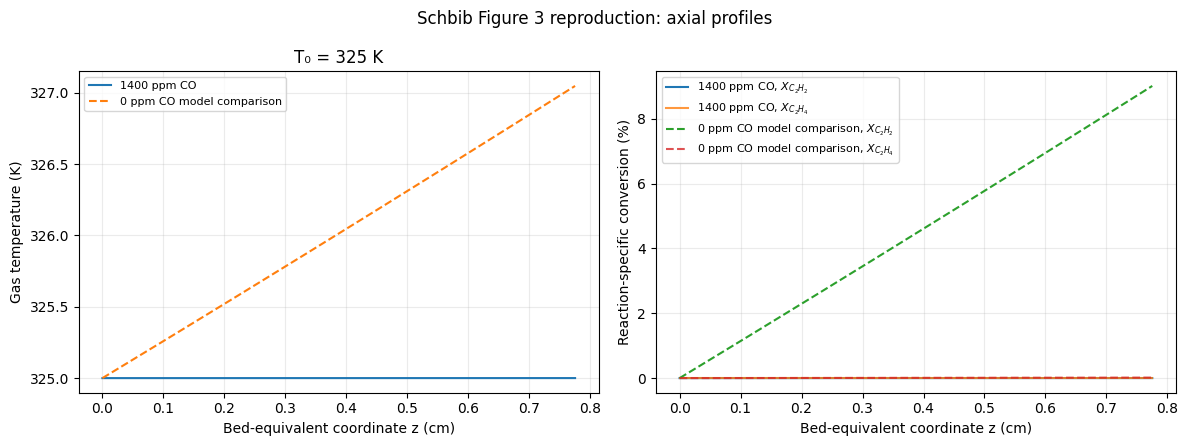

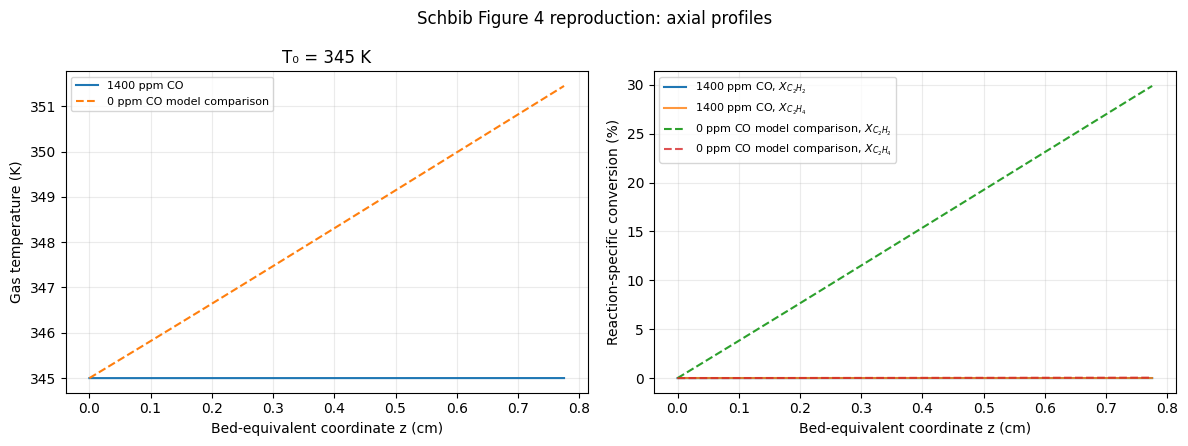

In [5]:
def plot_axial_case(T0_K, figure_number):
    fig, (ax_t, ax_x) = plt.subplots(1, 2, figsize=(12, 4.5))
    for co_ppm, style, label in ((1400.0, "-", "1400 ppm CO"), (0.0, "--", "0 ppm CO model comparison")):
        p = ModelParams(pressure_atm=16.3, T0_K=T0_K, CO_ppm=co_ppm, catalyst_mass_g=1.0)
        sol = run_pfr(p)
        z_cm = sol.t * 100.0
        x_a, x_e = conversion_profiles(sol, p)
        ax_t.plot(z_cm, sol.y[-1], style, label=label)
        ax_x.plot(z_cm, x_a * 100.0, style, label=label + r", $X_{C_2H_2}$")
        ax_x.plot(z_cm, x_e * 100.0, style, alpha=0.8, label=label + r", $X_{C_2H_4}$")
    ax_t.set(xlabel="Bed-equivalent coordinate z (cm)", ylabel="Gas temperature (K)",
             title=f"T₀ = {T0_K:.0f} K")
    ax_x.set(xlabel="Bed-equivalent coordinate z (cm)", ylabel="Reaction-specific conversion (%)")
    for ax in (ax_t, ax_x):
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(f"Schbib Figure {figure_number} reproduction: axial profiles")
    fig.tight_layout()
    fig.savefig(f"schbib_fig{figure_number}_axial_profiles.png", dpi=180, bbox_inches="tight")
    plt.show()

plot_axial_case(325.0, 3)
plot_axial_case(345.0, 4)

## Table 6 — direct conversion validation

Each row uses the reported 16 atm pressure, 100 cm³(STP)/min feed, and 1 g catalyst (SV = 100 cm³(STP) gcat⁻¹ min⁻¹). No kinetic parameters are adjusted. Errors are simulation minus measurement in percentage points.

In [6]:
table6_cases = [
    {"CO (ppm)": 150.0, "T (K)": 341.0, "X_C2H2 measured (%)": 98.31, "X_C2H4 measured (%)": 10.45},
    {"CO (ppm)": 1400.0, "T (K)": 359.0, "X_C2H2 measured (%)": 98.99, "X_C2H4 measured (%)": 6.70},
    {"CO (ppm)": 5000.0, "T (K)": 393.0, "X_C2H2 measured (%)": 98.62, "X_C2H4 measured (%)": 6.08},
]
validation_rows = []
for case in table6_cases:
    p = ModelParams(pressure_atm=16.0, T0_K=case["T (K)"], CO_ppm=case["CO (ppm)"], catalyst_mass_g=1.0)
    sol = run_pfr(p)
    x_a, x_e = conversion_profiles(sol, p)
    xa_sim = 100.0 * x_a[-1]
    xe_sim = 100.0 * x_e[-1]
    validation_rows.append({
        "CO (ppm)": case["CO (ppm)"], "T (K)": case["T (K)"],
        "C2H2 measured (%)": case["X_C2H2 measured (%)"], "C2H2 simulated (%)": xa_sim,
        "C2H2 error (pp)": xa_sim - case["X_C2H2 measured (%)"],
        "C2H4 measured (%)": case["X_C2H4 measured (%)"], "C2H4 simulated (%)": xe_sim,
        "C2H4 error (pp)": xe_sim - case["X_C2H4 measured (%)"],
        "T outlet (K)": sol.y[-1, -1],
    })
validation = pd.DataFrame(validation_rows)
display(validation.round(4))
print("No kinetic parameters were fitted. The displayed Table 6 errors are the direct result of the source-parameter model and must be read as a validation failure when they remain large.")

,CO (ppm),T (K),C2H2 measured (%),C2H2 simulated (%),C2H2 error (pp),C2H4 measured (%),C2H4 simulated (%),C2H4 error (pp),T outlet (K)
0,150.0,341.0,98.31,0.8467,-97.4633,10.45,0.0012,-10.4488,341.1834
1,1400.0,359.0,98.99,0.0099,-98.9801,6.70,0.0000,-6.7000,359.0020
2,5000.0,393.0,98.62,0.0018,-98.6182,6.08,0.0000,-6.0800,393.0003


No kinetic parameters were fitted. The displayed Table 6 errors are the direct result of the source-parameter model and must be read as a validation failure when they remain large.


## Interpretation and limitations

The Table 6 errors above are a direct, uncalibrated check of the simplified GOAL model. With the tabulated Arrhenius parameters interpreted as common logarithms, this implementation predicts very low conversions relative to Table 6; it therefore does **not** reproduce the measured conversions. The article reports a laboratory glycol bath and uses a more detailed heat/mass-transfer model for laboratory axial profiles; the present adiabatic pseudohomogeneous PFR omits those effects. The cause of the large discrepancy remains unresolved and requires checking the reported rate-parameter units/convention and model formulation against the authors' calculation. No parameter was adjusted.

The axial coordinate also depends on the documented effective-density convention because the article does not report a separate packed-bed void fraction or loaded bed length. Under the fixed Table 8 rates, the CO-free comparison does not show a large thermal runaway; this is another unmet reproduction target rather than a reason to alter the source kinetics. The no-CO curves are model comparisons, not additional experimental data.